# ESA WorldCover 2021 — Kraków

Odczyt fragmentu rastrowej mapy pokrycia terenu (10 m), wizualizacja, identyfikacja klas i zapis GeoTIFF.

Źródło: [ESA WorldCover](https://esa-worldcover.org/en/data-access). Dane: WorldCover 2021, v200.

## 1. Biblioteki

Wymagane: `rasterio`, `numpy`, `matplotlib`. Instalacja (w środowisku projektu): `pip install rasterio numpy matplotlib`.

In [1]:
import numpy as np
import rasterio
from rasterio.windows import from_bounds
import matplotlib.pyplot as plt

## 2. Odczyt fragmentu z serwera ESA

Plik jest typu Cloud Optimized GeoTIFF (COG). Odczytujemy wyłącznie fragment obejmujący Kraków. Współrzędne `bounds`: lewa, dolna, prawa, górna (długość i szerokość geograficzna, w stopniach).

In [2]:
url = (
    "https://esa-worldcover.s3.eu-central-1.amazonaws.com/"
    "v200/2021/map/"
    "ESA_WorldCover_10m_2021_v200_N48E018_Map.tif"
)

bounds = (19.75, 49.95, 20.15, 50.15)

with rasterio.open(url) as src:
    window = from_bounds(*bounds, transform=src.transform)
    window = window.round_offsets().round_lengths()
    landcover = src.read(1, window=window)
    profile = src.profile.copy()
    profile.update(
        height=landcover.shape[0],
        width=landcover.shape[1],
        transform=src.window_transform(window)
    )
    colors = src.colormap(1)
    print("CRS:", src.crs)
    print("Rozdzielczość (stopnie):", src.res)
    print("Fragment:", landcover.shape, landcover.dtype)

CRS: EPSG:4326
Rozdzielczość (stopnie): (8.333333333333333e-05, 8.333333333333333e-05)
Fragment: (2400, 4800) uint8


## 3. Wyświetlenie mapy

Kolory odczytujemy z oryginalnego pliku ESA; nie interpolujemy wartości klas.

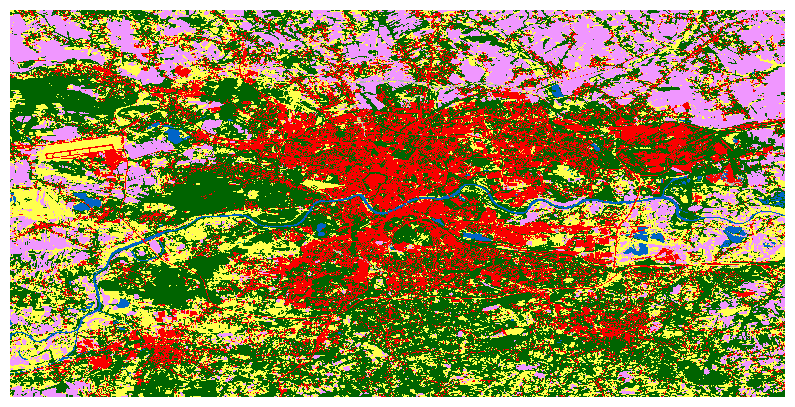

In [3]:
from matplotlib.colors import ListedColormap, BoundaryNorm

rgba = np.array([colors.get(i, (0, 0, 0, 0)) for i in range(256)]) / 255
cmap = ListedColormap(rgba)

plt.figure(figsize=(10, 7))
plt.imshow(landcover, cmap=cmap, vmin=0, vmax=255, interpolation="nearest")
plt.axis("off")
plt.show()

## 4. Klasy występujące w wybranym fragmencie

In [4]:
classes = {
    10: "Drzewa", 20: "Krzewy", 30: "Roślinność trawiasta",
    40: "Grunty uprawne", 50: "Zabudowa", 60: "Tereny bez roślinności",
    70: "Śnieg i lód", 80: "Woda", 90: "Mokradła zielne",
    95: "Namorzyny", 100: "Mchy i porosty"
}

values, counts = np.unique(landcover, return_counts=True)
for value, count in zip(values, counts):
    print(f"{value:3}  {classes.get(int(value), Nieznana):25} {count:>10} pikseli")

NameError: name 'Nieznana' is not defined

## 5. Proste maski rastrowe

In [ ]:
forest = landcover == 10
water = landcover == 80
built_up = landcover == 50

fig, axs = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, mask, title in zip(axs, (forest, water, built_up), ("Drzewa", "Woda", "Zabudowa")):
    ax.imshow(mask, cmap="gray", interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 6. Zapis lokalnego rastra GeoTIFF

In [ ]:
with rasterio.open("krakow_landcover.tif", "w", **profile) as dst:
    dst.write(landcover, 1)
    dst.write_colormap(1, colors)

print("Zapisano: krakow_landcover.tif")

**Uwaga:** raster pozostaje w EPSG:4326 (stopnie). Do obliczeń powierzchni i odległości należy go przekształcić do odpowiedniego układu metrycznego. Odczyt zdalny wymaga połączenia z internetem.